In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("All libraries imported successfully!")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

All libraries imported successfully!
Pandas: 3.1.0
NumPy: 2.5.2
Scikit-learn: 1.9.1


In [2]:
from pathlib import Path

project_dir = Path.cwd().parent
data_dir = project_dir / "data" / "raw"

print("Project directory:", project_dir)
print("Data folder exists:", data_dir.exists())
print("Files in data folder:", list(data_dir.glob("*")))

Project directory: c:\Users\hp\Desktop\python\House_Price_prediction
Data folder exists: True
Files in data folder: [WindowsPath('c:/Users/hp/Desktop/python/House_Price_prediction/data/raw/test.csv'), WindowsPath('c:/Users/hp/Desktop/python/House_Price_prediction/data/raw/train.csv')]


In [3]:
import pandas as pd
import numpy as np

# Load the datasets
train_path = data_dir / "train.csv"
test_path = data_dir / "test.csv"

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print("Training dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)

Training dataset shape: (1460, 81)
Testing dataset shape: (1459, 80)


In [4]:
train_df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [5]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [6]:
print("Duplicate rows:", train_df.duplicated().sum())

print("\nTarget column:")
print(train_df["SalePrice"].describe())

Duplicate rows: 0

Target column:
count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


In [7]:
# Count missing values in each column
missing_count = train_df.isnull().sum()

# Keep only columns that have missing values
missing_count = missing_count[missing_count > 0]

# Calculate missing percentage
missing_percentage = (
    missing_count / len(train_df) * 100
).round(2)

# Combine both into one report
missing_report = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percentage": missing_percentage
})

# Show columns with the most missing values first
missing_report = missing_report.sort_values(
    by="Missing_Percentage",
    ascending=False
)

missing_report

,Missing_Count,Missing_Percentage
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


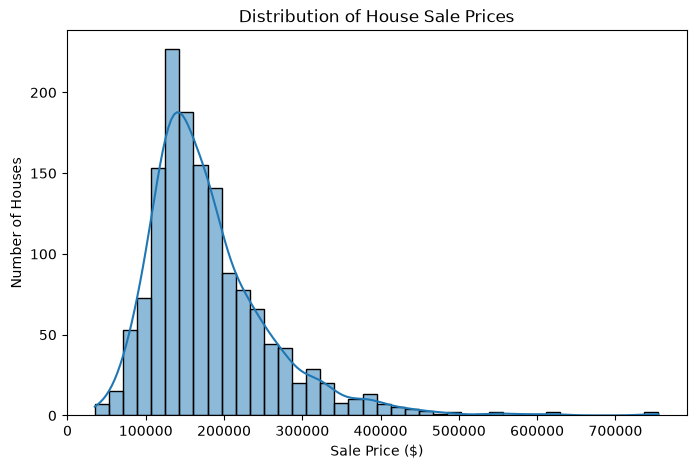

In [8]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=train_df,
    x="SalePrice",
    bins=40,
    kde=True
)

plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price ($)")
plt.ylabel("Number of Houses")

plt.show()

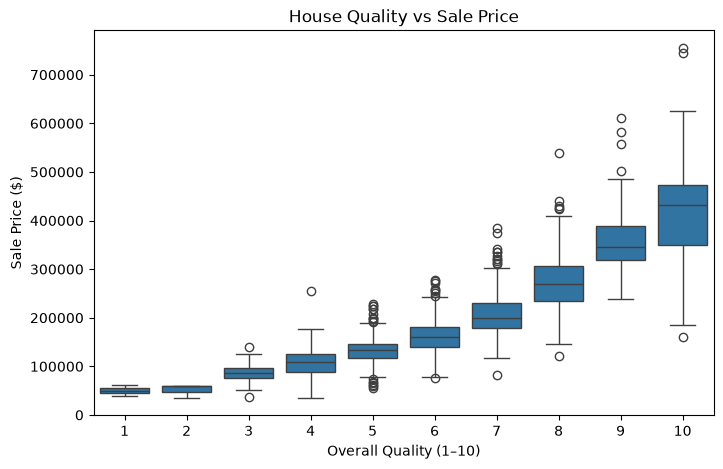

In [9]:
# Relationship between overall house quality and sale price
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=train_df,
    x="OverallQual",
    y="SalePrice"
)

plt.title("House Quality vs Sale Price")
plt.xlabel("Overall Quality (1–10)")
plt.ylabel("Sale Price ($)")
plt.show()

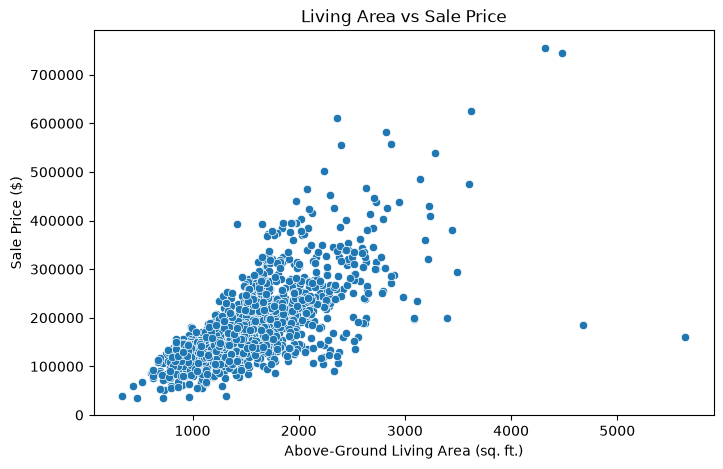

In [10]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=train_df,
    x="GrLivArea",
    y="SalePrice"
)

plt.title("Living Area vs Sale Price")
plt.xlabel("Above-Ground Living Area (sq. ft.)")
plt.ylabel("Sale Price ($)")
plt.show()

In [11]:
# Select only numeric columns
numeric_df = train_df.select_dtypes(include="number")

# Calculate correlation with SalePrice
price_correlation = numeric_df.corr()["SalePrice"]

# Sort from strongest positive to strongest negative
price_correlation = price_correlation.sort_values(
    ascending=False
)

price_correlation.head(10)

SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
Name: SalePrice, dtype: float64

In [12]:
# Check skewness of SalePrice
print("SalePrice skewness:", train_df["SalePrice"].skew())

SalePrice skewness: 1.8828757597682118


In [13]:
# Create a transformed target for experimentation
train_df["LogSalePrice"] = np.log1p(train_df["SalePrice"])

print("Original skewness:", train_df["SalePrice"].skew())
print("Log skewness:", train_df["LogSalePrice"].skew())

Original skewness: 1.8828757597682118
Log skewness: 0.12134661989686531


In [14]:
# Columns that contain missing values
missing_cols = train_df.columns[train_df.isnull().any()]

# Inspect their data types
missing_details = pd.DataFrame({
    "Data_Type": train_df[missing_cols].dtypes,
    "Missing_Count": train_df[missing_cols].isnull().sum()
})

missing_details

,Data_Type,Missing_Count
LotFrontage,float64,259
Alley,str,1369
MasVnrType,str,872
MasVnrArea,float64,8
BsmtQual,str,37
BsmtCond,str,37
BsmtExposure,str,38
BsmtFinType1,str,37
BsmtFinType2,str,38
Electrical,str,1
